In [51]:
import pandas as pd
import os
import matplotlib.pyplot as plt
import seaborn as sb
import numpy as np

In [6]:
# setup variables
param_1 = 'Match proportion'
param_2 = 'Trim quality'
output_folders = ['../misc_data/S1-OUTPUT_extracted', '../misc_data/S2-OUTPUT_extracted', '../misc_data/S3-OUTPUT_extracted']
# Exclude this outlier from the combined heatmap
excluded_combined_samples = {'fish23_s15_rep2'}

In [7]:
# Read the parameter table for each dataset
parameters_by_folder = {
    output_folder: (
        pd.read_csv(f'{output_folder}/parameters.csv')
        .drop_duplicates()
        .set_index('Directory name')
    )
    for output_folder in output_folders
}
next(iter(parameters_by_folder.values())).head()

,Match proportion,Match count,Trim quality,Trim window
Directory name,,,,
S1_MP0.75_MC25_TQ8_TW5-OUTPUT,0.75,25,8,5
S1_MP0.75_MC25_TQ10_TW5-OUTPUT,0.75,25,10,5
S1_MP0.75_MC25_TQ12_TW5-OUTPUT,0.75,25,12,5
S1_MP0.75_MC25_TQ14_TW5-OUTPUT,0.75,25,14,5
S1_MP0.75_MC25_TQ16_TW5-OUTPUT,0.75,25,16,5


In [8]:
output_dirs_by_folder = {
    output_folder: list(parameters_df.index)
    for output_folder, parameters_df in parameters_by_folder.items()
}

In [9]:
# Read and append data for each dataset
allreadcounts_by_folder = {}
for output_folder, output_dirs in output_dirs_by_folder.items():
    allreadcounts_dfs = []
    for output_dir in output_dirs:
        output_path = f'{output_folder}/{output_dir}'
        for fish in sorted(os.listdir(output_path)):
            # Output directories also contain an html report directory. Only
            # load sample directories that contain the expected count file.
            allreadcounts_path = f'{output_path}/{fish}/{fish}.allReadCounts'
            if not os.path.isfile(allreadcounts_path):
                continue
            fish_df = pd.read_csv(allreadcounts_path, sep='\t')
            # Header-only files are valid empty outputs, but including them
            # makes pandas coerce numeric columns to object dtype during concat.
            if fish_df.empty:
                continue
            fish_df['Directory name'] = output_dir
            fish_df['Fish'] = fish
            allreadcounts_dfs.append(fish_df)
    if not allreadcounts_dfs:
        raise ValueError(f'No non-empty .allReadCounts files found in {output_folder}')
    allreadcounts_by_folder[output_folder] = allreadcounts_dfs

next(iter(allreadcounts_by_folder.values()))[0].head()

,event,array,count,proportion,Directory name,Fish
0,NONE_12D+65_NONE_NONE_17D+133_NONE_NONE_NONE_N...,0,4605,0.278231,S1_MP0.75_MC25_TQ8_TW5-OUTPUT,fish14_s8_rep2
1,4D+32&6I+40+CCTATC_6D+59_NONE_NONE_1D+145_3D+1...,1,3346,0.202163,S1_MP0.75_MC25_TQ8_TW5-OUTPUT,fish14_s8_rep2
2,4D+32&6I+40+CCTATC_6D+59_NONE_NONE_NONE_NONE_N...,2,2696,0.162890,S1_MP0.75_MC25_TQ8_TW5-OUTPUT,fish14_s8_rep2
3,4D+32&6I+40+CCTATC_6D+59_NONE_NONE_NONE_NONE_5...,3,1830,0.110567,S1_MP0.75_MC25_TQ8_TW5-OUTPUT,fish14_s8_rep2
4,1D+38_78D+62_78D+62_78D+62_NONE_8D+173_2D+201_...,4,553,0.033412,S1_MP0.75_MC25_TQ8_TW5-OUTPUT,fish14_s8_rep2


In [10]:
results_by_folder = {}
for output_folder, allreadcounts_dfs in allreadcounts_by_folder.items():
    parameters_df = parameters_by_folder[output_folder]
    results_df = pd.concat(allreadcounts_dfs, ignore_index=True)
    for col in parameters_df.columns:
        results_df[col] = results_df['Directory name'].map(parameters_df[col])
    results_by_folder[output_folder] = results_df

next(iter(results_by_folder.values())).head()

,event,array,count,proportion,Directory name,Fish,Match proportion,Match count,Trim quality,Trim window
0,NONE_12D+65_NONE_NONE_17D+133_NONE_NONE_NONE_N...,0,4605,0.278231,S1_MP0.75_MC25_TQ8_TW5-OUTPUT,fish14_s8_rep2,0.75,25,8,5
1,4D+32&6I+40+CCTATC_6D+59_NONE_NONE_1D+145_3D+1...,1,3346,0.202163,S1_MP0.75_MC25_TQ8_TW5-OUTPUT,fish14_s8_rep2,0.75,25,8,5
2,4D+32&6I+40+CCTATC_6D+59_NONE_NONE_NONE_NONE_N...,2,2696,0.162890,S1_MP0.75_MC25_TQ8_TW5-OUTPUT,fish14_s8_rep2,0.75,25,8,5
3,4D+32&6I+40+CCTATC_6D+59_NONE_NONE_NONE_NONE_5...,3,1830,0.110567,S1_MP0.75_MC25_TQ8_TW5-OUTPUT,fish14_s8_rep2,0.75,25,8,5
4,1D+38_78D+62_78D+62_78D+62_NONE_8D+173_2D+201_...,4,553,0.033412,S1_MP0.75_MC25_TQ8_TW5-OUTPUT,fish14_s8_rep2,0.75,25,8,5


In [14]:
# Calculate each sample's singleton proportion before combining datasets.
# Samples are identified by both source folder and Fish to avoid collisions.
sample_summaries = []
for output_folder, results_df in results_by_folder.items():
    sample_df = (
        results_df.assign(is_singleton=results_df['count'].eq(1))
        .groupby([param_1, param_2, 'Fish'])
        .agg(
            total_entries=('count', 'sum'),
            singleton_entries=('is_singleton', 'sum'),
        )
        .reset_index()
    )
    sample_df['Output folder'] = output_folder
    sample_df['singleton_entry_proportion'] = (
        sample_df['singleton_entries'] / sample_df['total_entries'].replace(0, np.nan)
    )
    sample_summaries.append(sample_df)

sample_info_df = pd.concat(sample_summaries, ignore_index=True)
combined_sample_info_df = sample_info_df.loc[
    ~sample_info_df['Fish'].isin(excluded_combined_samples)
]
# Each sample contributes equally; pandas std uses sample SD (ddof=1).
# Empty count files have no defined proportion and are excluded, not set to zero.
info_df = (
    combined_sample_info_df.groupby([param_1, param_2])
    .agg(
        mean_proportion=('singleton_entry_proportion', 'mean'),
        std_proportion=('singleton_entry_proportion', 'std'),
        sample_count=('singleton_entry_proportion', 'count'),
    )
    .reset_index()
)

info_df.head()

,Match proportion,Trim quality,mean_proportion,std_proportion,sample_count
0,0.75,8,0.019756,0.011644,17
1,0.75,10,0.019750,0.011651,17
2,0.75,12,0.019737,0.011650,17
3,0.75,14,0.036118,0.018294,17
4,0.75,16,0.024159,0.013453,17


In [15]:
plt.style.use('default')
plt.rcParams.update(small_label_settings)

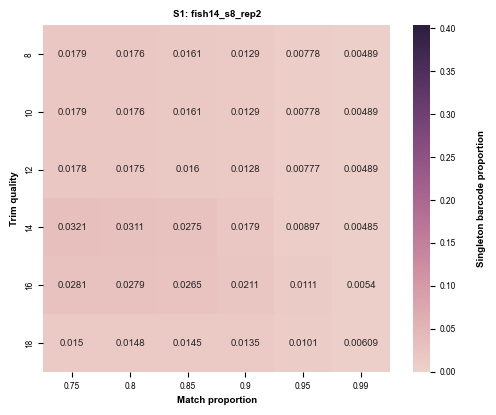

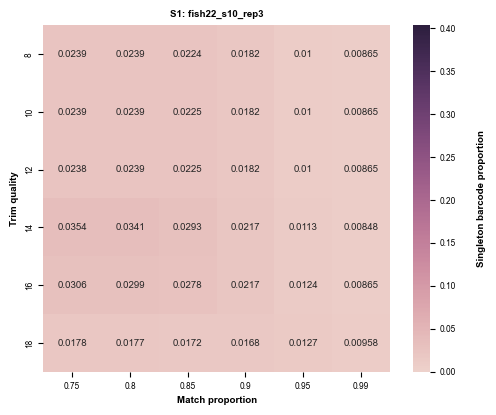

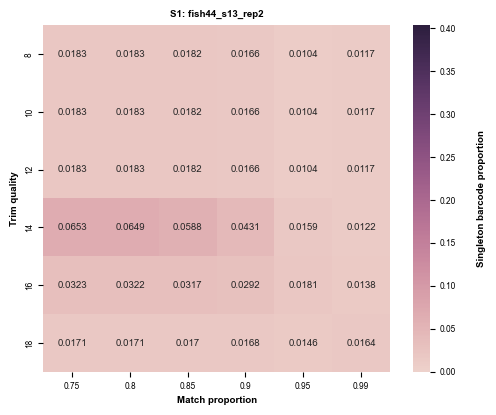

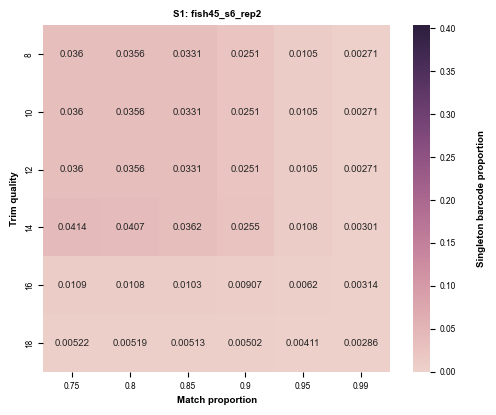

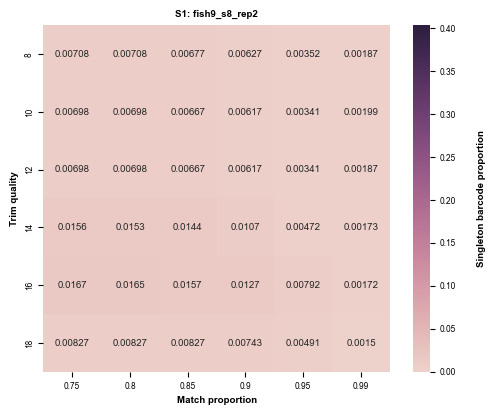

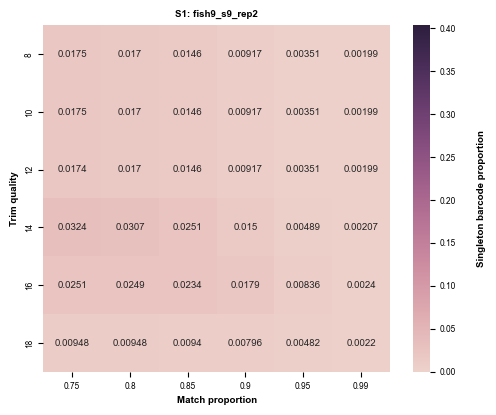

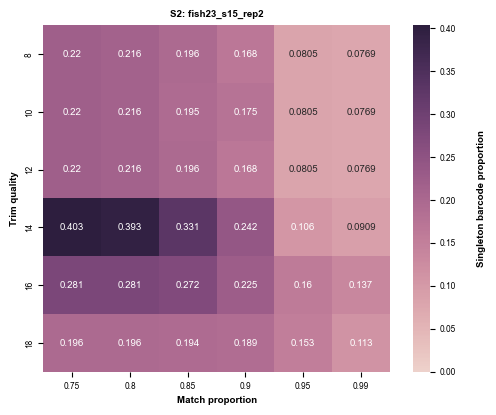

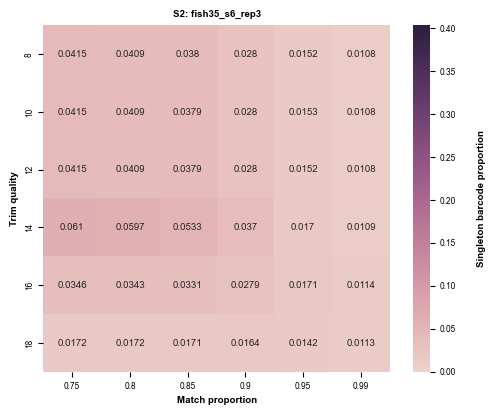

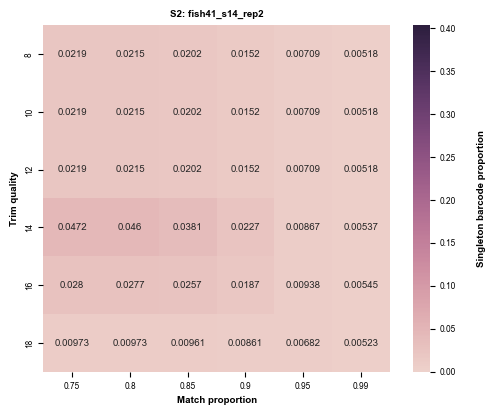

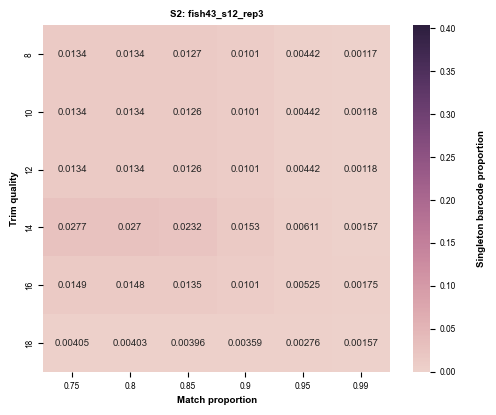

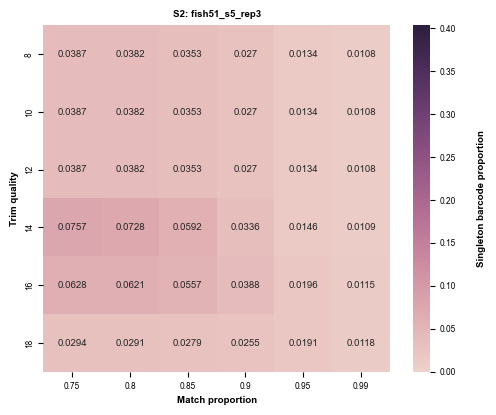

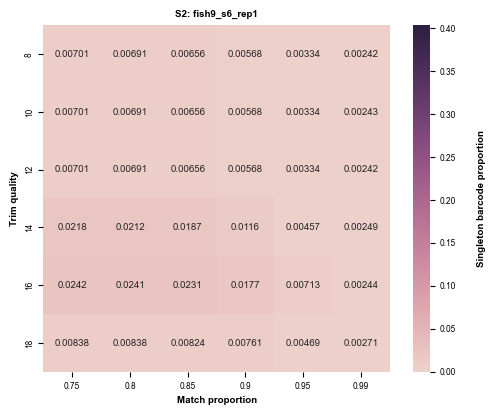

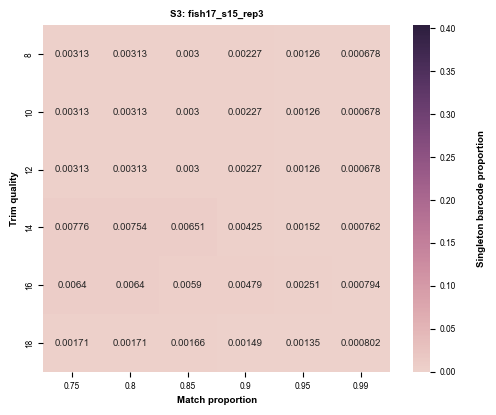

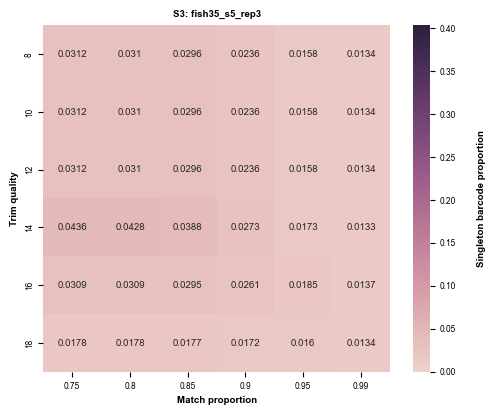

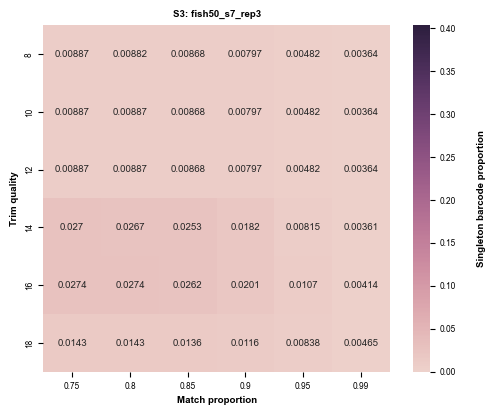

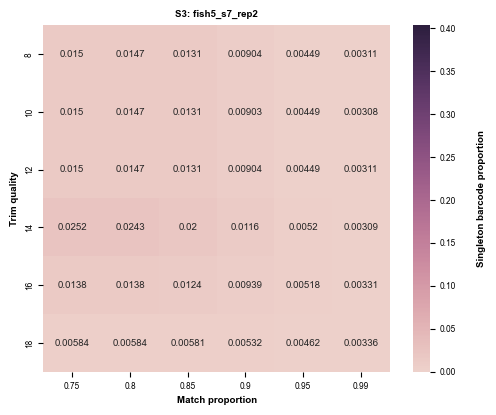

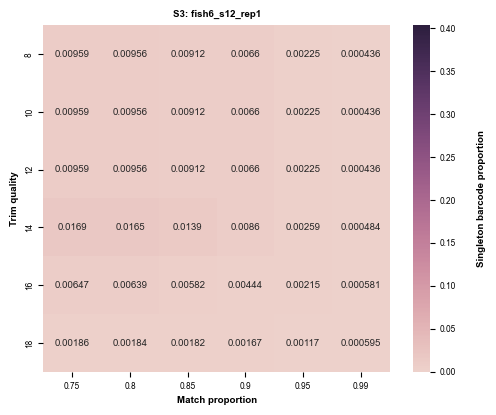

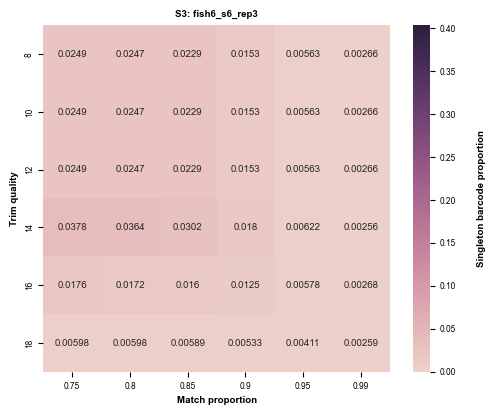

In [18]:
# One heatmap per sample (18 total for S1, S2, and S3).
sample_image_dir = 'images/singleton_proportion_samples'
os.makedirs(sample_image_dir, exist_ok=True)

# Share axes and color limits so samples can be compared directly.
trim_values = sorted(sample_info_df[param_2].unique())
match_values = sorted(sample_info_df[param_1].unique())
sample_vmax = sample_info_df['singleton_entry_proportion'].max()

for (output_folder, fish), sample_data in sample_info_df.groupby(['Output folder', 'Fish']):
    dataset_name = os.path.basename(os.path.normpath(output_folder))
    dataset_name = dataset_name.removesuffix('-OUTPUT_extracted')
    sample_pivot = sample_data.pivot(
        index=param_2, columns=param_1, values='singleton_entry_proportion',
    ).reindex(index=trim_values, columns=match_values)

    sample_fig, sample_ax = plt.subplots(figsize=(6, 4.5))
    sb.heatmap(
        sample_pivot,
        annot=True,
        fmt='.3g',
        square=True,
        cmap=sb.cubehelix_palette(as_cmap=True),
        vmin=0,
        vmax=sample_vmax,
        ax=sample_ax,
        annot_kws={'size': 7},
    )
    sample_ax.set_title(f'{dataset_name}: {fish}', fontweight='bold')
    sample_ax.set_xlabel(param_1, fontweight='bold')
    sample_ax.set_ylabel(param_2, fontweight='bold')
    sample_ax.collections[0].colorbar.set_label(
        'Singleton barcode proportion', labelpad=15, fontweight='bold',
    )

    sample_output_stem = f'{sample_image_dir}/{dataset_name}_{fish}'
    sample_fig.savefig(f'{sample_output_stem}.png', dpi=300, bbox_inches='tight')
    sample_fig.savefig(f'{sample_output_stem}.svg', bbox_inches='tight')
    plt.show()
    plt.close(sample_fig)

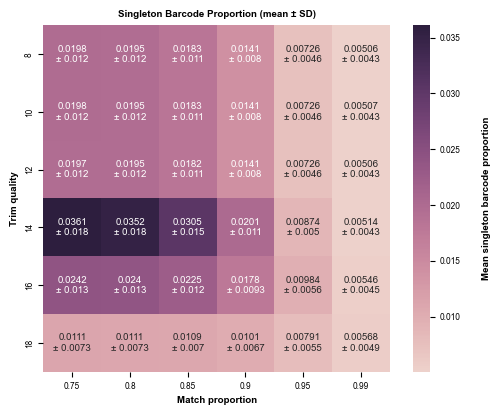

In [19]:
# One combined heatmap: color = mean; annotation = mean +/- sample SD.
pivot_data = info_df.pivot(
    index=param_2, columns=param_1, values='mean_proportion',
)
std_data = info_df.pivot(
    index=param_2, columns=param_1, values='std_proportion',
).reindex(index=pivot_data.index, columns=pivot_data.columns)
annotations = np.array([
    [f'{mean:.3g}\n± {sd:.2g}' for mean, sd in zip(means, sds)]
    for means, sds in zip(pivot_data.to_numpy(), std_data.to_numpy())
])

fig, ax = plt.subplots(figsize=(6, 4.5))
sb.heatmap(
    pivot_data,
    annot=annotations,
    fmt='',
    square=True,
    cmap=sb.cubehelix_palette(as_cmap=True),
    ax=ax,
    annot_kws={'size': 7},
)

ax.set_title('Singleton Barcode Proportion (mean ± SD)', fontweight='bold')
ax.set_xlabel(param_1, fontweight='bold')
ax.set_ylabel(param_2, fontweight='bold')
cbar = ax.collections[0].colorbar
cbar.set_label('Mean singleton barcode proportion', labelpad=15, fontweight='bold')

output_stem = 'images/singleton_proportion_combined'
fig.savefig(f'{output_stem}.png', dpi=300, bbox_inches='tight')
fig.savefig(f'{output_stem}.svg', bbox_inches='tight')
plt.show()

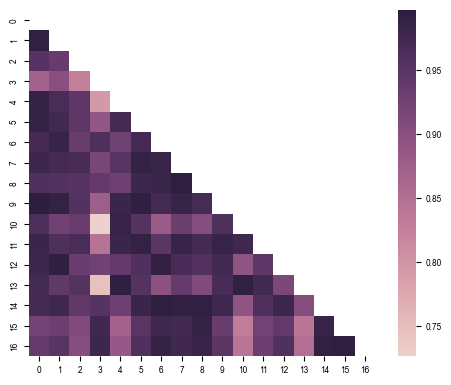

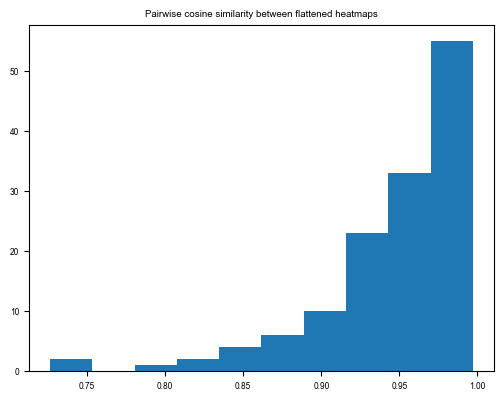

np.float64(0.9462061547975118)

In [50]:
from sklearn.metrics.pairwise import cosine_similarity

# Store flattened heatmaps
n = len(combined_sample_info_df['Fish'].unique())
# heatmap rows x cols = 36
flat_mtx = np.zeros((36, n))
for i, ((output_folder, fish), sample_data) in enumerate(combined_sample_info_df.groupby(['Output folder', 'Fish'])):
    dataset_name = os.path.basename(os.path.normpath(output_folder))
    dataset_name = dataset_name.removesuffix('-OUTPUT_extracted')
    sample_pivot = sample_data.pivot(
        index=param_2, columns=param_1, values='singleton_entry_proportion',
    ).reindex(index=trim_values, columns=match_values)
    flat_mtx[:, i] = sample_pivot.values.flatten()

cosine = cosine_similarity(flat_mtx.T)

cosine[np.triu_indices_from(cosine, k=0)] = np.nan

fig, ax = plt.subplots(figsize=(6, 4.5))
sb.heatmap(
    cosine,
    #annot=annotations,
    fmt='',
    square=True,
    cmap=sb.cubehelix_palette(as_cmap=True),
    ax=ax,
    annot_kws={'size': 7},
)

fig, ax = plt.subplots(figsize=(6, 4.5))
ax.hist(cosine.flatten()[~np.isnan(cosine.flatten())])
ax.set_title('Pairwise cosine similarity between flattened heatmaps')
plt.show()
cosine.flatten()[~np.isnan(cosine.flatten())].mean()